## 4. Modélisation et évaluation

Cette partie construit et compare des modèles de prévision du trafic horaire. Pour juger leur performance, on utilise quatre métriques : la MAE et la RMSE (erreurs en nombre de véhicules, la RMSE pénalisant davantage les pics mal anticipés), le R² (part de la variance expliquée) et le WAPE (erreur en % du volume total). Tout modèle est comparé à une **baseline** simple : le trafic de la veille à la même heure (`lag_24h`).

### 4.1 Préparation des données et découpage chronologique
On charge les données nettoyées, on ajoute les variables calendaires et les lags (trafic de la veille et de la semaine précédente), puis on sépare le jeu en deux. Pour une série temporelle, le découpage ne peut pas être aléatoire : on entraîne sur le passé (jusqu'à fin mars 2018) et on teste sur la période la plus récente (à partir d'avril 2018), comme en situation réelle.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
from src.clean import load_and_clean_data
from src.features import add_time_features, add_lag_features
from src.evaluate import evaluate, baseline_scores, cross_validate_ts
from src.train import prepare_dataset, split_train_test, get_model, train_model, FEATURES, TARGET

df = load_and_clean_data("../data/raw/Metro_Interstate_Traffic_Volume.csv")
df = prepare_dataset(add_lag_features(add_time_features(df)))
train, test = split_train_test(df)
print("Train :", train.shape, "| Test :", test.shape)

Train : (23903, 17) | Test : (4392, 17)


### 4.2 Comparaison des modèles
On compare trois approches sur le jeu de test : une **baseline** (trafic de la veille à la même heure), une **régression linéaire** (modèle simple et interprétable) et une **Random Forest** (capable de capter des relations non linéaires, comme les heures de pointe).

In [2]:
resultats = {'Baseline (veille)': baseline_scores(test)}
modeles = {'Régression linéaire': 'linear', 'Random Forest': 'random_forest'}

for libelle, nom in modeles.items():
    modele = train_model(train, nom)
    resultats[libelle] = evaluate(test[TARGET], modele.predict(test[FEATURES]))

display(pd.DataFrame(resultats).T)

/Users/timandradhenry/Desktop/Traffic_Forecasting_MLOps/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/timandradhenry/Desktop/Traffic_Forecasting_MLOps/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/timandradhenry/Desktop/Traffic_Forecasting_MLOps/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


,MAE,RMSE,R2,WAPE_%
Baseline (veille),539.6,1018.9,0.735,16.1
Régression linéaire,311.5,554.4,0.922,9.3
Random Forest,239.7,439.2,0.951,7.2


### 4.3 Validation croisée temporelle
Un seul découpage dépend de la période choisie pour le test. Pour vérifier que les résultats sont stables, on répète l'évaluation sur plusieurs périodes successives de trois mois : à chaque fois, le modèle est entraîné sur tout le passé et testé sur la période qui suit.

In [3]:
cv = cross_validate_ts(get_model('random_forest', n_estimators=50), df, FEATURES)
display(cv)
print("Moyenne :", cv.mean().round(1).to_dict())

,MAE,RMSE,R2,WAPE_%
0,237.4,400.5,0.960,6.9
1,325.6,551.8,0.922,9.9
2,320.0,542.0,0.924,9.8
3,251.8,460.8,0.949,7.5
4,219.9,410.9,0.955,6.6


Moyenne : {'MAE': 270.9, 'RMSE': 473.2, 'R2': 0.9, 'WAPE_%': 8.1}


### 4.4 Interprétation du modèle
On regarde quelles variables pèsent le plus dans les prédictions de la Random Forest, puis on compare visuellement les prévisions et le trafic réel sur une semaine du jeu de test. Cela permet de vérifier que le modèle suit bien les pics du matin et du soir.

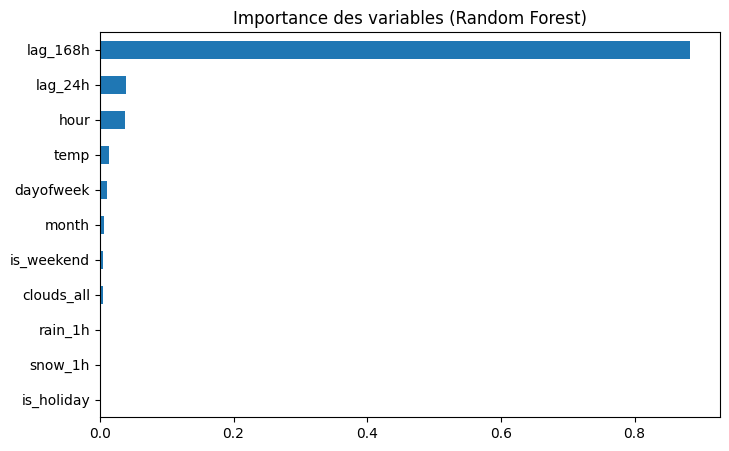

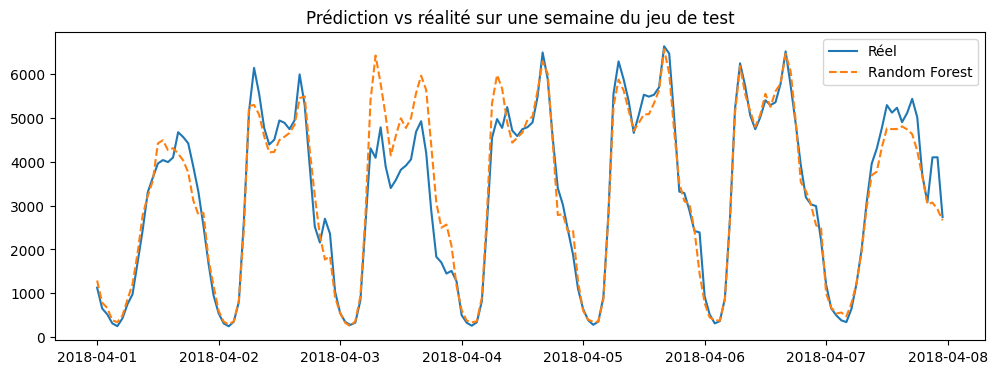

In [4]:
rf = train_model(train, 'random_forest')

# Importance des variables
importances = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
importances.plot(kind='barh', figsize=(8, 5), title="Importance des variables (Random Forest)")
plt.show()

# Une semaine du jeu de test : réel vs prédit
semaine = test.iloc[:168]
plt.figure(figsize=(12, 4))
plt.plot(semaine['date_time'], semaine[TARGET], label='Réel')
plt.plot(semaine['date_time'], rf.predict(semaine[FEATURES]), label='Random Forest', linestyle='--')
plt.legend()
plt.title("Prédiction vs réalité sur une semaine du jeu de test")
plt.show()

**Lecture du graphique.** Sur la semaine du 1er au 7 avril 2018, la Random Forest reproduit bien le rythme quotidien du trafic : creux de nuit et pics du matin et du soir en semaine. Les écarts les plus visibles concernent certains pics, par exemple le 3 avril où le modèle surestime nettement le trafic. Une explication probable est que le modèle s'appuie surtout sur le trafic de la semaine précédente à la même heure (`lag_168h`) : il se trompe donc quand une journée s'écarte du schéma habituel (météo, événement, jour particulier).

**Implication métier.** Pour la régulation du trafic, le modèle est fiable pour anticiper les périodes de forte affluence, ce qui permet de préparer les mesures à l'avance. Les jours atypiques restent plus difficiles à prévoir, et les prévisions de ces jours-là demandent plus de prudence.